        # Which forecast goes to the plan, how many packer shifts a week, and what does a miss cost?

        **Week 4, Friday, chapter 3 of 3.** **The ticket.** Flipkart, the Lucknow fulfilment centre (FC), the warehouse where orders are packed
and shipped. The centre has 104 weeks of outbound shipments, the weeks beginning Monday 30 September
2024 to Monday 21 September 2026. Diwali fell on Thursday 31 October 2024 and Monday 20 October 2025,
and falls on Sunday 8 November 2026; the festive sale runs in the third and second weeks before
Diwali's week. A packer packs about 120 shipments a shift, and a packer-shift is one packer working
one shift. The planner must book packer shifts for the eight weeks beginning 12 October to 30
November 2026, the festive window. A vendor's demand model promises the window 22 percent above the
same weeks last year; finance's rule is those weeks plus 4 percent: eighteen percentage points apart.
A late shipment costs Rs 25 (assumed, Rs 15 to 40). A spare shipment, planned for and never shipped,
leaves part of a packer-shift idle: Rs 650 a shift (assumed, Rs 500 to 800) over 120 shipments, Rs
5.42 a shipment. Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

        Chapter 2 scored every rule on thirteen hidden summer weeks: festival-aligned and finance's
        rule tied at 6,615 a week, the house bot scored 9,831, the vendor 16,400. None of those
        weeks held a festival, so the hold-out could not test the one thing the plan depends on.

        **Who needs the answer.** The FC planner, who books the shifts, and the regional operations
        head, who answers for late parcels in the festival's busiest weeks. A plan that puts the
        peak in the wrong week pays for idle packers and late shipments in the same month.

        **The questions on the way.** How did each rule do on 2025's festival? Which week does each
        forecast put this year's peak in? How do the four forecasts compare with last year's two
        windows? How far above the forecast should the plan sit, and why? How many shifts a week?
        What would the other plans cost?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
vendor = pd.read_csv("../data/C2_W04_D05_vendor_forecast_STUDENT.csv", parse_dates=["week_start"])
costs = pd.read_csv("../data/C2_W04_D05_costs_STUDENT.csv").set_index("item").rs
y = weekly.set_index("week_start").shipments
v = vendor.set_index("week_start").vendor_shipments
spare_rs = costs["idle_packer_shift"] / 120          # an idle shift's Rs 650 over 120 shipments: Rs 5.42
late_rs = costs["late_shipment"]                      # Rs 25 a late shipment
diwali = {2024: pd.Timestamp("2024-10-28"), 2025: pd.Timestamp("2025-10-20"), 2026: pd.Timestamp("2026-11-02")}

source = {}                                           # week -> the week festival-aligned copies for it
for d in pd.date_range(y.index[52], "2026-11-30", freq="7D"):   # every week with a year of weeks behind it
    source[d] = d - pd.Timedelta(weeks=52)            # outside the stretch: the same calendar week
    for year, w in diwali.items():
        gap = (d - w).days // 7                       # weeks from that year's Diwali week; -5 is five before
        if -5 <= gap <= 4 and year - 1 in diwali:
            source[d] = diwali[year - 1] + pd.Timedelta(weeks=gap)   # the same distance from last year's Diwali

print(f"a spare shipment costs Rs {spare_rs:.2f}; a late one Rs {late_rs}")
print(source[pd.Timestamp("2026-10-19")].date(), "is the source for the week of 19 Oct 2026")
check("the week of 19 Oct 2026 copies 6 Oct 2025", source[pd.Timestamp("2026-10-19")] == pd.Timestamp("2025-10-06"))

a spare shipment costs Rs 5.42; a late one Rs 25
2025-10-06 is the source for the week of 19 Oct 2026
PASS the week of 19 Oct 2026 copies 6 Oct 2025


## How did each rule do on 2025's festival?

The only festival the data can test the rules on is 2025's. A **back-test** stands at an
earlier date and forecasts what came next as if the later weeks were unknown: stand in the
week of 22 September 2025 and forecast the eight weeks from 29 September to 17 November
2025. Festival-aligned copies, from five weeks before Diwali's week to four after, the week
at the same distance from last year's Diwali. One honest caveat: the 4 percent growth was
measured later, on weeks up to June 2026, so the cell also runs festival-aligned with no
growth, as a planner in September 2025 could have.

**Predict before you run.** By how many weeks does the house bot miss 2025's peak?

a) none: same week last year knows the season
b) one week late
c) one week early
d) two weeks late

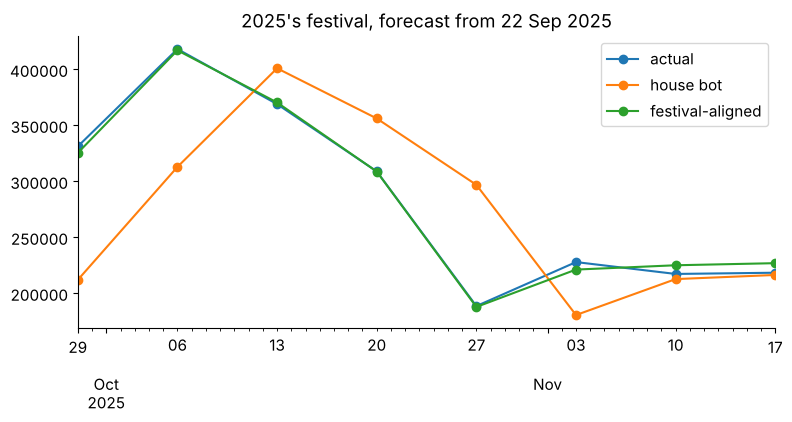

house bot: MAE 58,250; spare Rs 10.2 lakh, late Rs 69.6 lakh, total Rs 79.8 lakh
finance: MAE 60,488; spare Rs 13.0 lakh, late Rs 60.9 lakh, total Rs 73.9 lakh
festival-aligned: MAE 4,034; spare Rs 1.0 lakh, late Rs 3.6 lakh, total Rs 4.6 lakh
aligned, no growth: MAE 10,575; spare Rs 0.0 lakh, late Rs 21.1 lakh, total Rs 21.1 lakh
overtime shifts: 1,638 in the week of 6 Oct 2025, 5 in the week of 24 Nov 2025
PASS the bot's peak is 13 Oct 2025, a week late
PASS festival-aligned peaks on 6 Oct 2025 with the actual


In [2]:
weeks25 = pd.date_range("2025-09-29", periods=8, freq="7D")        # 29 Sep to 17 Nov 2025
back = pd.DataFrame({
    "actual": y.loc[weeks25],
    "house bot": [y[d - pd.Timedelta(weeks=52)] for d in weeks25],
    "finance": [round(y[d - pd.Timedelta(weeks=52)] * 1.04) for d in weeks25],
    "festival-aligned": [round(y[source[d]] * 1.04) for d in weeks25],
    "aligned, no growth": [y[source[d]] for d in weeks25],
}, index=weeks25)
back[["actual", "house bot", "festival-aligned"]].plot(marker="o", title="2025's festival, forecast from 22 Sep 2025")
plt.show()
for rule in ["house bot", "finance", "festival-aligned", "aligned, no growth"]:
    miss = back[rule] - back.actual                                  # positive: too high
    spare = miss[miss > 0].sum() * spare_rs
    late = -miss[miss < 0].sum() * late_rs
    print(f"{rule}: MAE {miss.abs().mean():,.0f}; spare Rs {spare / 100_000:.1f} lakh, "
          f"late Rs {late / 100_000:.1f} lakh, total Rs {(spare + late) / 100_000:.1f} lakh")
overtime = weekly.set_index("week_start").overtime_shifts
print(f"overtime shifts: {overtime['2025-10-06']:,} in the week of 6 Oct 2025, {overtime['2025-11-24']} in the week of 24 Nov 2025")
check("the bot's peak is 13 Oct 2025, a week late", back["house bot"].idxmax() == pd.Timestamp("2025-10-13"))
check("festival-aligned peaks on 6 Oct 2025 with the actual", back["festival-aligned"].idxmax() == back.actual.idxmax())

**What happened.** The answer is b. The house bot put 2024's peak on 13 October 2025, a
week late: MAE 58,250 and Rs 79.8 lakh of misses, Rs 69.6 lakh of it late shipments in the
weeks where 2025's rush came before the copy expected it. Finance's rule, the same copy plus
4 percent, missed by 60,488 a week. Festival-aligned missed by 4,034 a week and Rs 4.6 lakh,
and with no growth added it still missed by only 10,575. One festival is a thin test, so the
plan treats this as evidence about placement, never as a precise error.

## Which week does each forecast put this year's peak in?

Diwali 2026 falls on Sunday 8 November, so its week begins 2 November, and the sale, and
with it the peak, should come two weeks before, in the week of 19 October.

**Predict before you run.** Which week does the house bot's copy of 2025 make the busiest
week of the festive season?

a) 5 October 2026
b) 19 October 2026
c) 26 October 2026
d) 2 November 2026

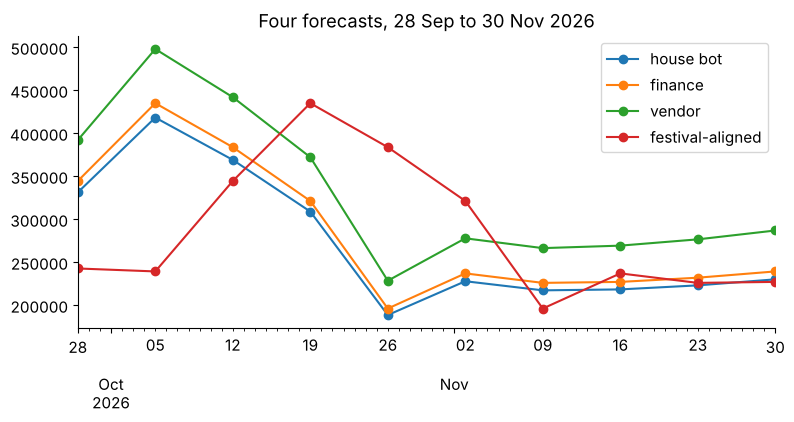

house bot           2026-10-05
finance             2026-10-05
vendor              2026-10-05
festival-aligned    2026-10-19
PASS the bot's busiest week is 5 Oct 2026
PASS festival-aligned's busiest week is 19 Oct 2026


In [3]:
weeks26 = pd.date_range("2026-09-28", periods=10, freq="7D")        # 28 Sep to 30 Nov 2026
ahead = pd.DataFrame({
    "house bot": [y[d - pd.Timedelta(weeks=52)] for d in weeks26],
    "finance": [round(y[d - pd.Timedelta(weeks=52)] * 1.04) for d in weeks26],
    "vendor": v.loc[weeks26].values,
    "festival-aligned": [round(y[source[d]] * 1.04) for d in weeks26],
}, index=weeks26)
ahead.plot(marker="o", title="Four forecasts, 28 Sep to 30 Nov 2026")
plt.show()
print(ahead.idxmax().dt.date.to_string())
check("the bot's busiest week is 5 Oct 2026", ahead["house bot"].idxmax() == pd.Timestamp("2026-10-05"))
check("festival-aligned's busiest week is 19 Oct 2026", ahead["festival-aligned"].idxmax() == pd.Timestamp("2026-10-19"))

**What happened.** The answer is a. The house bot, finance's rule and the vendor all make 5
October 2026 the busiest week, because each copies 2025's calendar weeks; festival-aligned
puts it on 19 October, two weeks before Diwali's week. The window the planner books starts
a week after 5 October, so inside it the calendar copies book the most for 12 October
(369,000 from the house bot) and far too little for 19 and 26 October (308,900 and 188,600),
when festival-aligned expects 434,928 and 383,760. The vendor's model never knew the
festival moved.

## How do the four forecasts compare with last year's window?

"Last year's window" has two readings. The same calendar weeks, 13 October to 1 December
2025, hold only the tail of 2025's festival. The same weeks counted from Diwali, 29
September to 17 November 2025, hold all of it.

In [4]:
window = weeks26[2:]                                    # 12 Oct to 30 Nov 2026, the weeks to book
calendar_2025 = y.loc[window - pd.Timedelta(weeks=52)].sum()
festival_2025 = y.loc[[source[d] for d in window]].sum()
totals = ahead.loc[window].sum()
compare = pd.DataFrame({"eight weeks": totals.map("{:,}".format),
                        "vs same calendar weeks": (totals / calendar_2025 - 1).map("{:+.1%}".format),
                        "vs same weeks from Diwali": (totals / festival_2025 - 1).map("{:+.1%}".format)})
print(f"2025, same calendar weeks: {calendar_2025:,}   2025, same weeks from Diwali: {festival_2025:,}")
print(compare.to_string())
print(f"finance below festival-aligned: {totals['festival-aligned'] - totals['finance']:,} shipments")
check("finance is plus 4 percent on the calendar window", round(totals["finance"] / calendar_2025 - 1, 3) == 0.04)
check("the vendor is plus 22 percent on the calendar window", round(totals["vendor"] / calendar_2025 - 1, 3) == 0.22)
check("finance sits below festival-aligned", totals["finance"] < totals["festival-aligned"])

2025, same calendar weeks: 1,983,300   2025, same weeks from Diwali: 2,279,500
                 eight weeks vs same calendar weeks vs same weeks from Diwali
house bot          1,983,300                  +0.0%                    -13.0%
finance            2,062,632                  +4.0%                     -9.5%
vendor             2,419,500                 +22.0%                     +6.1%
festival-aligned   2,370,680                 +19.5%                     +4.0%
finance below festival-aligned: 308,048 shipments
PASS finance is plus 4 percent on the calendar window
PASS the vendor is plus 22 percent on the calendar window
PASS finance sits below festival-aligned


**What happened.** Against the calendar weeks, festival-aligned reads 19.5 percent above
last year, close to the vendor's 22.0, because 2026's peak weeks fall inside the window and
2025's fell before it. Against the weeks counted from Diwali it reads 4.0 percent. Finance's
plus 4 is plus 4 only on the calendar window: against last year's festival weeks it sits
9.5 percent below, and against festival-aligned's forecast it is 308,048 shipments short,
on the costly side. The vendor's total sits 2.1 percent above festival-aligned, with its
busiest week on 5 October.

## How far above the forecast should the plan sit, and why?

Raise the plan by one shipment and two things can happen. If demand turns out higher, that
shipment is no longer late, which saves Rs 25. If demand turns out lower, it is a spare
shipment, which wastes Rs 5.42. Picture 100 weeks. If demand beats the plan in 18 of them,
one more shipment of plan saves 18 x Rs 25 = Rs 450 and wastes 82 x Rs 5.42 = Rs 444: about
even, so stop there. That is the rule, called the newsvendor rule after a seller deciding
how many papers to stock: plan so that demand is covered in this share of weeks.

$$\text{share covered} = \frac{\text{late cost}}{\text{late cost} + \text{spare cost}} = \frac{25}{25 + 5.42} \approx 0.82$$

Then read the 0.82 point off the forecast's own misses on the hidden weeks of chapter 2.
Here the miss is measured the other way round: how far demand came **above** the forecast,
as a share of it, so a positive number is a week the forecast was too low.

In [5]:
hold = y.iloc[91:]                                              # chapter 2's thirteen hidden weeks
fa_hold = (y.shift(52).loc[hold.index] * 1.04).round()          # festival-aligned on them
above = (hold - fa_hold) / fa_hold                              # demand above the forecast, as a share
print("demand above the forecast, percent, smallest first:")
print((above * 100).round(1).sort_values().to_list())
q = late_rs / (late_rs + spare_rs)                              # the share of weeks to cover
cushion = round(above.quantile(q), 3)                           # 0.82 of the way along the sorted thirteen
covered = (above <= cushion).sum()
print(f"cover {q:.2f} of weeks: raise the forecast by {cushion:.1%}, which covers {covered} of the 13 weeks")
raised = fa_hold * (1 + cushion)
gap = raised - hold                                             # positive: spare
raised_cost = (gap[gap > 0].sum() * spare_rs - gap[gap < 0].sum() * late_rs) / 100_000
print(f"raised by {cushion:.1%}, these weeks' misses cost Rs {raised_cost:.1f} lakh, read from the same weeks")
check("the plan share is about 0.82", round(q, 2) == 0.82)
check("the cushion sits between the 10th and 11th sorted weeks",
      sorted(above)[9] <= cushion <= sorted(above)[10])

demand above the forecast, percent, smallest first:
[-5.9, -5.1, -3.0, -2.1, -1.8, -0.4, 0.4, 1.5, 1.7, 2.1, 2.7, 5.4, 7.8]
cover 0.82 of weeks: raise the forecast by 2.6%, which covers 10 of the 13 weeks
raised by 2.6%, these weeks' misses cost Rs 8.8 lakh, read from the same weeks
PASS the plan share is about 0.82
PASS the cushion sits between the 10th and 11th sorted weeks


**What happened.** Sorted, the thirteen weeks run from 5.9 percent below the forecast to
7.8 percent above. The 0.82 point sits between the 10th week, 2.1 percent, and the 11th,
2.7 percent; `quantile` reads it 0.82 of the way along the list, at 2.6 percent. The raised
forecast covers 10 of the 13 weeks, and the 11th misses by a hair. With thirteen weeks the
true point could sit anywhere from about 2 to 3 percent; the curve below shows why that
stretch costs almost the same.

## How does a week's cost change as the plan is raised?

Try every level of plan on the busiest week, 19 October 2026, and for each level replay
the thirteen hidden-week misses as thirteen possible demands; average their costs.

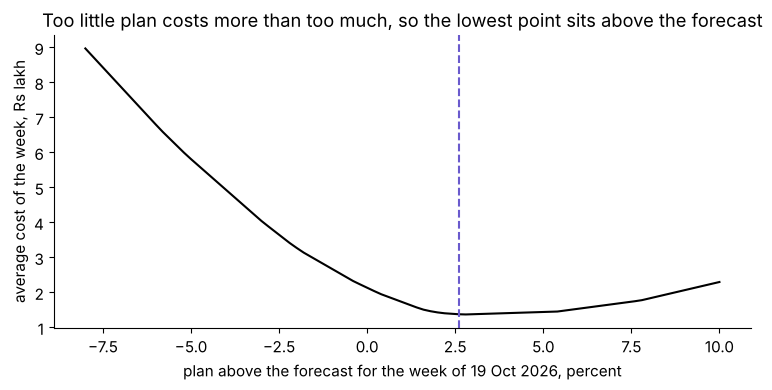

the lowest cost sits 2.8% above the forecast; the plan takes 2.6%
PASS the cheapest level sits above the forecast


In [6]:
base = ahead.loc["2026-10-19", "festival-aligned"]            # the plan's busiest week
levels = [i / 1000 for i in range(-80, 101, 2)]               # 8 percent below to 10 percent above
cost_at = []
for g in levels:                                              # each way the plan could be raised
    plan_level = base * (1 + g)
    total = 0
    for a in above:                                           # each past miss, as a possible demand
        demand = base * (1 + a)
        total += max(0, plan_level - demand) * spare_rs + max(0, demand - plan_level) * late_rs
    cost_at.append(total / len(above) / 100_000)              # the week's average cost, Rs lakh
plt.plot([g * 100 for g in levels], cost_at, color="black")
plt.axvline(cushion * 100, ls="--", color="slateblue")
plt.xlabel("plan above the forecast for the week of 19 Oct 2026, percent")
plt.ylabel("average cost of the week, Rs lakh")
plt.title("Too little plan costs more than too much, so the lowest point sits above the forecast")
plt.show()
lowest = levels[cost_at.index(min(cost_at))]
print(f"the lowest cost sits {lowest:.1%} above the forecast; the plan takes {cushion:.1%}")
check("the cheapest level sits above the forecast", lowest > 0)

## How many packer shifts does each week need?

The plan raises each week of the festival-aligned forecast by the 2.6 percent cushion, then
divides by 120 shipments a shift and rounds up.

            forecast    plan  packer shifts
2026-10-12    344448  353404           2946
2026-10-19    434928  446236           3719
2026-10-26    383760  393738           3282
2026-11-02    321256  329609           2747
2026-11-09    196144  201244           1678
2026-11-16    237016  243178           2027
2026-11-23    225992  231868           1933
2026-11-30    227136  233042           1943
total: 20,275 packer shifts over eight weeks; the forecast alone needs 19,760, so the cushion adds 515


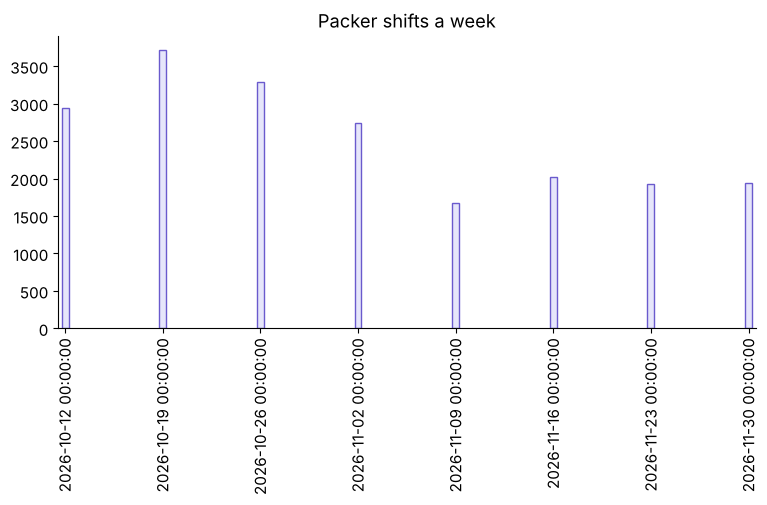

PASS the busiest week of the plan is 19 Oct 2026


In [7]:
plan = (ahead.loc[window, "festival-aligned"] * (1 + cushion)).round()
shifts = (plan / 120).apply(math.ceil)
plain = (ahead.loc[window, "festival-aligned"] / 120).apply(math.ceil)    # the forecast with no cushion
staffing = pd.DataFrame({"forecast": ahead.loc[window, "festival-aligned"], "plan": plan.astype(int),
                         "packer shifts": shifts})
print(staffing.to_string())
print(f"total: {shifts.sum():,} packer shifts over eight weeks; the forecast alone needs {plain.sum():,}, "
      f"so the cushion adds {shifts.sum() - plain.sum():,}")
staffing["packer shifts"].plot.bar(color="lavender", edgecolor="slateblue", title="Packer shifts a week")
plt.show()
check("the busiest week of the plan is 19 Oct 2026", staffing["packer shifts"].idxmax() == pd.Timestamp("2026-10-19"))

## What would the other plans cost if demand follows the festival-aligned forecast?

A scenario, never a measurement: if festival-aligned is right about where the rush falls,
what does booking by each other forecast cost? Each plan is priced against festival-aligned's
weeks, Rs 5.42 for every spare shipment and Rs 25 for every shipment short. The 2025
back-test is the evidence that festival-aligned places the rush well; this table prices
being wrong about it.

In [8]:
expected = ahead.loc[window, "festival-aligned"]               # demand, if festival-aligned is right
booked = {"house bot": ahead.loc[window, "house bot"], "finance": ahead.loc[window, "finance"],
          "vendor": ahead.loc[window, "vendor"], "plan": plan}
scenario = {}
for name, b in booked.items():
    gap = b - expected                                         # positive: spare capacity
    scenario[name] = (gap[gap > 0].sum() * spare_rs - gap[gap < 0].sum() * late_rs) / 100_000
    print(f"{name}: Rs {scenario[name]:.1f} lakh")
check("the plan costs least in this scenario", min(scenario, key=scenario.get) == "plan")

house bot: Rs 111.6 lakh
finance: Rs 103.6 lakh
vendor: Rs 82.2 lakh
plan: Rs 3.3 lakh
PASS the plan costs least in this scenario


**What happened.** If demand follows festival-aligned, the house bot's weeks cost Rs 111.6
lakh, finance's Rs 103.6 lakh and the vendor's Rs 82.2 lakh, mostly late shipments in the
weeks of 19 October to 2 November. The plan's cushion costs Rs 3.3 lakh of spare shifts if
demand lands exactly on the forecast: the price of the insurance.

## What can two years of weeks not tell us?

- **The festival moves, and the sale moves with it.** Tested on one festival only: the 2025
  back-test.
- **Two years hold only two festivals,** so the festival's shape rests on two examples; no
  check inside the data closes that.
- **The hidden weeks hold no festive week,** so their 6,615 is an ordinary-week error; the
  2025 festival gave 4,034 on one festival.
- **Capacity caps the peak.** Overtime reached 1,638 shifts in the week of 6 October 2025
  against 5 in the week of 24 November 2025, as the back-test cell printed, so peak demand
  may have run above what shipped.
- **The 4 percent growth** is two years' evidence; a third year could move it.
- **The vendor's model has never forecast a Lucknow festival it had not seen,** so its
  festive numbers are an untested assumption.

## The same method at an AI company: how much inference capacity does a launch need?

**Inference** is the computing a model does each time it answers a user. A product launch
is the festival: a known date, a spike, little history. Line the last launch up by days from
launch day, hide as many days as the plan covers, score in requests a minute, beat the last
launch's shape, and set capacity above the forecast, because a timeout costs more than an
idle server.

## What did chapter 3 answer?

- **2025's festival:** the house bot landed the peak a week late (Rs 79.8 lakh of misses);
  festival-aligned missed by Rs 4.6 lakh.
- **This year's peak:** the house bot, finance and the vendor put it on 5 October 2026;
  festival-aligned on 19 October.
- **Last year's windows:** festival-aligned is 19.5 percent above the calendar weeks and 4.0
  percent above the weeks from Diwali; finance is 9.5 percent below the festival weeks.
- **How far above:** cover 0.82 of weeks, a 2.6 percent cushion.
- **Shifts:** 20,275 over eight weeks, 3,719 in the week of 19 October.
- **The others' cost:** Rs 82.2 to 111.6 lakh if demand follows festival-aligned; the
  cushion Rs 3.3 lakh.